# Лабораторная работа 4

Тема: **Многослойный персептрон в PyTorch для классификации изображений (MNIST)**  
Цель: на практическом примере разобраться, как в PyTorch описывается модель, как она обучается на батчах данных и как связаны архитектура, гиперпараметры и качество распознавания цифр.

> ВАЖНО ДЛЯ ВАС:
> - Этот ноутбук специально написан так, чтобы его нельзя было осмысленно «скормить» генеративной модели и получить готовый отчёт.  
> - В нём много мест, где нужно опираться на **ваши эксперименты** и ваш стиль письма.  
> - Преподаватель смотрит на согласованность: код ↔ графики ↔ текст. Шаблонные ответы и типовой «ИИ‑стиль» легко заметны.


## 1. Ваше понимание задачи (коротко, по‑человечески)

Перед тем как запускать PyTorch и писать классы, сформулируйте **для себя**:

1. Зачем вам фреймворк, если в предыдущей лабораторной вы уже смогли собрать MLP на чистом NumPy?  
2. Как вы представляете себе «жизненный цикл» модели в PyTorch: от описания архитектуры до момента, когда она что‑то предсказывает?  
3. Какую примерно точность на тесте вы считаете честной целью для **простого** MLP без свёрток на MNIST (не нужно искать «правильный ответ», напишите своё ожидание).

Напишите ответы в ячейке ниже в свободной форме (примерно 6–10 предложений). Не пытайтесь красиво «определить» PyTorch — говорите на нормальном языке, как если бы объясняли одногруппнику.


In [65]:
intro_text = """
1. Потому что фреймворки предоставляют более удобные интерфейсы взаимодействия, что ускоряет процесс разработки.
По мимо этого, фреймворк PyTorch отлажен и оттестирован. Самописный MLP подходит для понимания того, как он работает 
2. Описание архитектуры -> Подготовка датасета(загрузка данных, нормализация) -> Выбираем функцию потерь и оптимизатор -> Обучаем модель -> 
Смотрим оценки (loss, accuracy) -> Если данные удовлеторяют, то используем модель для предсказаний.
3. от 97.5%
"""
print(intro_text)


1. Потому что фреймворки предоставляют более удобные интерфейсы взаимодействия, что ускоряет процесс разработки.
По мимо этого, фреймворк PyTorch отлажен и оттестирован. Самописный MLP подходит для понимания того, как он работает 
2. Описание архитектуры -> Подготовка датасета(загрузка данных, нормализация) -> Выбираем функцию потерь и оптимизатор -> Обучаем модель -> 
Смотрим оценки (loss, accuracy) -> Если данные удовлеторяют, то используем модель для предсказаний.
3. от 97.5%



## 2. Импорт библиотек и настройка

Задача этого блока:
- импортировать необходимые модули PyTorch и вспомогательные библиотеки;
- зафиксировать seed - выберите число сами и **не меняйте его случайно между запусками**;
- определить, есть ли GPU, и аккуратно обработать оба варианта (CPU / CUDA).

Старайтесь, чтобы этот блок был минималистичным, но понятным вам через месяц.


In [66]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

# Выберите и зафиксируйте свой seed (запишите число отдельно в отчёте)
MY_SEED = 1  # можете поменять, но затем используйте это значение последовательно
torch.manual_seed(MY_SEED)
np.random.seed(MY_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Используемое устройство:", device)
print("MY_SEED =", MY_SEED)

Используемое устройство: cpu
MY_SEED = 1


## 3. Подготовка данных MNIST

Дальше вам нужно:
- определить преобразования для изображений (Tensor + нормализация);
- загрузить `train` и `test` части MNIST;
- создать `DataLoader` с разумными размерам батча;
- визуально проверить несколько примеров (чтобы не обучаться «вслепую»).

Нормализацию можно сделать стандартной для MNIST или подобрать свою. В отчёте потом объясните, что выбрали и почему.


Размер train: 60000
Размер test : 10000
batch_size = 64
Ваши mean=-0.0001, std=1.0000
Стандартные: mean=0.1307, std=0.3081


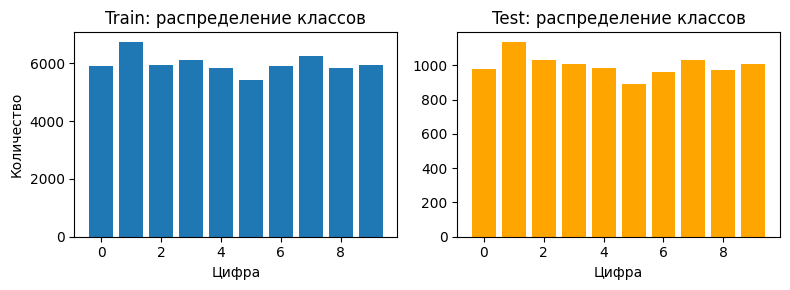

In [67]:
# ПОДГОТОВКА ПРЕОБРАЗОВАНИЙ
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))  # можно поменять, но тогда прокомментируйте это в отчёте
])

# ЗАГРУЗКА ДАТАСЕТА
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform,
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform,
)

# РАЗМЕР БАТЧА: выберите сами и при защите объясните, почему именно такой
batch_size = 64

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print("Размер train:", len(train_dataset))
print("Размер test :", len(test_dataset))
print("batch_size =", batch_size)

all_pixels = torch.cat([img.view(-1) for img, _ in train_dataset])
mean = all_pixels.mean().item()
std  = all_pixels.std().item()
print(f"Ваши mean={mean:.4f}, std={std:.4f}")
print(f"Стандартные: mean=0.1307, std=0.3081")

all_labels = [lbl for _, lbl in train_dataset]
unique, counts = np.unique(all_labels, return_counts=True)

plt.figure(figsize=(8, 3))
plt.subplot(1, 2, 1)
plt.bar(unique, counts)
plt.title("Train: распределение классов")
plt.xlabel("Цифра"); plt.ylabel("Количество")

test_labels = [lbl for _, lbl in test_dataset]
unique_t, counts_t = np.unique(test_labels, return_counts=True)
plt.subplot(1, 2, 2)
plt.bar(unique_t, counts_t, color="orange")
plt.title("Test: распределение классов")
plt.xlabel("Цифра")
plt.tight_layout(); plt.show()

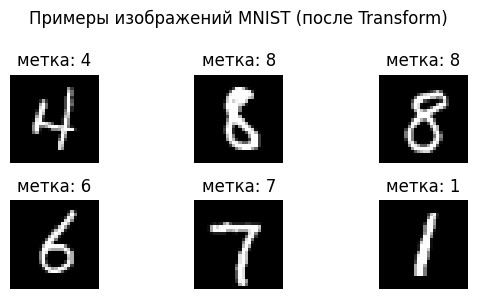

In [68]:
# ВИЗУАЛЬНАЯ ПРОВЕРКА НЕСКОЛЬКИХ ПРИМЕРОВ
images, labels = next(iter(train_loader))

plt.figure(figsize=(6, 3))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i].squeeze().numpy(), cmap="gray")
    plt.title(f"метка: {labels[i].item()}")
    plt.axis("off")

plt.suptitle("Примеры изображений MNIST (после Transform)")
plt.tight_layout()
plt.show()

### Краткий комментарий к данным (заполните сами)

Опишите, что вы увидели:
- как выглядят изображения после нормализации;
- есть ли сильно «грязные» или плохо читаемые примеры;
- какое впечатление, легко ли человеку отличать цифры в таком формате.

Это не формальная часть - просто зафиксируйте свои наблюдения.


In [69]:
data_comment = """
Изображения выглядят четко и контрастно после нормализации. 
Есть примеры плохо читаемых цифр, но их не так уж много. 
Человеку будет легко отличить цифры в таком формате
"""
print(data_comment)


Изображения выглядят четко и контрастно после нормализации. 
Есть примеры плохо читаемых цифр, но их не так уж много. 
Человеку будет легко отличить цифры в таком формате



## 4. Архитектура многослойного персептрона

Теперь нужно описать модель.

**Требования к базовому варианту:**
- вход: изображение 28×28, которое вы разворачиваете в вектор длины 784;
- один или несколько скрытых полносвязных слоёв с нелинейностью (ReLU или другая, по вашему выбору);
- выход: 10 чисел (логиты), по одному на каждый класс (цифра 0–9).

Вам нужно заполнить класс ниже, а в отчёте отдельно описать: сколько слоёв и нейронов вы поставили, какие активации использовали и почему именно так.


In [ ]:
class MNISTMLP(nn.Module):
    def __init__(self):
        super().__init__()
        # TODO: замените архитектуру на свою (изменения архитектуры должны сопровождаться пояснениями)
        self.flatten = nn.Flatten()
        self.net = nn.Sequential(
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.net(x)
        return logits

model = MNISTMLP().to(device)
print(model)

MNISTMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (net): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 5. Функция потерь и оптимизатор

Для многоклассовой классификации на MNIST обычно используют:
- `nn.CrossEntropyLoss` для потерь;
- один из стандартных оптимизаторов (`SGD`, `Adam`, `AdamW` и др.).

Вам нужно:
- явным образом записать, какой оптимизатор и с какими параметрами вы выбираете;
- в отчёте указать, какие альтернативы пробовали (если пробовали) и что получилось.


In [71]:
criterion = nn.CrossEntropyLoss()

# Попробуйте несколько вариантов lr и типов оптимизаторов в разных запусках и сравните разные комбинации
learning_rate = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

print("Функция потерь:", criterion)
print("Оптимизатор:", optimizer)
print("learning_rate =", learning_rate)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Число обучаемых параметров:", total_params)


Функция потерь: CrossEntropyLoss()
Оптимизатор: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
learning_rate = 0.001
Число обучаемых параметров: 235146


## 6. Функции обучения и оценки модели

Ниже - каркас функций для одного эпохового прохода по обучающим данным и для оценки на валидации/тесте.

Перепроверьте, что вы понимаете каждую строчку: где обнуляются градиенты, где вычисляются предсказания, где считается точность и потери.

Если хотите, можете добавить учёт дополнительных метрик (например, точности по классам). Главное - не потерять базовую ясность.


In [72]:
def train_one_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    running_correct = 0
    total = 0

    for images, labels in dataloader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        running_correct += (preds == labels).sum().item()
        total += images.size(0)

    epoch_loss = running_loss / total
    epoch_acc = running_correct / total
    return epoch_loss, epoch_acc


def evaluate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    running_correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            running_correct += (preds == labels).sum().item()
            total += images.size(0)

    epoch_loss = running_loss / total
    epoch_acc = running_correct / total
    return epoch_loss, epoch_acc

print("Функции train_one_epoch и evaluate определены.")

Функции train_one_epoch и evaluate определены.


## 7. Обучение модели: история потерь и точности

Теперь запускаем обучение на несколько эпох.

**Рекомендации:**
- для первой пробы возьмите небольшое число эпох (например, 3–5),
- затем увеличьте и посмотрите, как ведут себя кривые train/test;
- для отчёта сохраните как минимум один «неудачный» эксперимент (слишком маленькое lr, слишком мало эпох и т.д.) - он полезнее, чем идеальная картинка.


In [73]:
num_epochs = 15  # изменяйте это значение и фиксируйте результаты в отчёте

history = {
    "train_loss": [],
    "train_acc": [],
    "test_loss": [],
    "test_acc": []
}

for epoch in range(1, num_epochs + 1):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, device)
    test_loss, test_acc = evaluate(model, test_loader, criterion, device)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["test_loss"].append(test_loss)
    history["test_acc"].append(test_acc)

    print(f"Эпоха {epoch}/{num_epochs}: "
          f"train_loss={train_loss:.4f}, train_acc={train_acc:.4f}, "
          f"test_loss={test_loss:.4f}, test_acc={test_acc:.4f}")

Эпоха 1/15: train_loss=0.2585, train_acc=0.9214, test_loss=0.1173, test_acc=0.9609
Эпоха 2/15: train_loss=0.1200, train_acc=0.9633, test_loss=0.0922, test_acc=0.9719
Эпоха 3/15: train_loss=0.0907, train_acc=0.9718, test_loss=0.0870, test_acc=0.9731
Эпоха 4/15: train_loss=0.0773, train_acc=0.9758, test_loss=0.0840, test_acc=0.9758
Эпоха 5/15: train_loss=0.0645, train_acc=0.9788, test_loss=0.0755, test_acc=0.9780
Эпоха 6/15: train_loss=0.0582, train_acc=0.9811, test_loss=0.0770, test_acc=0.9777
Эпоха 7/15: train_loss=0.0513, train_acc=0.9830, test_loss=0.0759, test_acc=0.9772
Эпоха 8/15: train_loss=0.0471, train_acc=0.9848, test_loss=0.0689, test_acc=0.9794
Эпоха 9/15: train_loss=0.0433, train_acc=0.9860, test_loss=0.0756, test_acc=0.9786
Эпоха 10/15: train_loss=0.0403, train_acc=0.9866, test_loss=0.0730, test_acc=0.9795
Эпоха 11/15: train_loss=0.0378, train_acc=0.9878, test_loss=0.0683, test_acc=0.9818
Эпоха 12/15: train_loss=0.0330, train_acc=0.9888, test_loss=0.0708, test_acc=0.9814
Э

In [74]:
lr_optim_comment = """ЗДЕСЬ УКАЖИТЕ ЗАПУСКИ ОБУЧЕНИЯ С РАЗНЫМИ ОПТИМИЗАТОРАМИ И СКОРОСТЯМИ ОБУЧЕНИЯ.
Например: 
optimizer = SGD; lr = 1e-3; num_epochs = 5; test_acc = 0.9765
optimizer = AdamW; lr = 1e-3; num_epochs = 5; test_acc = 0.9816
optimizer = AdamW; lr = 15e-4; num_epochs = 5; test_acc = 0.9801
optimizer = AdamW; lr = 2e-3; num_epochs = 5; test_acc = 0.9770
optimizer = Adam; lr = 1e-3; num_epochs = 5; test_acc = 0.9820
optimizer = Adam; lr = 1e-3; num_epochs = 10; test_acc = 0.9826
optimizer = Adam; lr = 1e-3; num_epochs = 15; test_acc = 0.9797
"""
print(lr_optim_comment)

ЗДЕСЬ УКАЖИТЕ ЗАПУСКИ ОБУЧЕНИЯ С РАЗНЫМИ ОПТИМИЗАТОРАМИ И СКОРОСТЯМИ ОБУЧЕНИЯ.
Например: 
optimizer = SGD; lr = 1e-3; num_epochs = 5; test_acc = 0.9765
optimizer = AdamW; lr = 1e-3; num_epochs = 5; test_acc = 0.9816
optimizer = AdamW; lr = 15e-4; num_epochs = 5; test_acc = 0.9801
optimizer = AdamW; lr = 2e-3; num_epochs = 5; test_acc = 0.9770
optimizer = Adam; lr = 1e-3; num_epochs = 5; test_acc = 0.9820
optimizer = Adam; lr = 1e-3; num_epochs = 10; test_acc = 0.9826
optimizer = Adam; lr = 1e-3; num_epochs = 15; test_acc = 0.9797



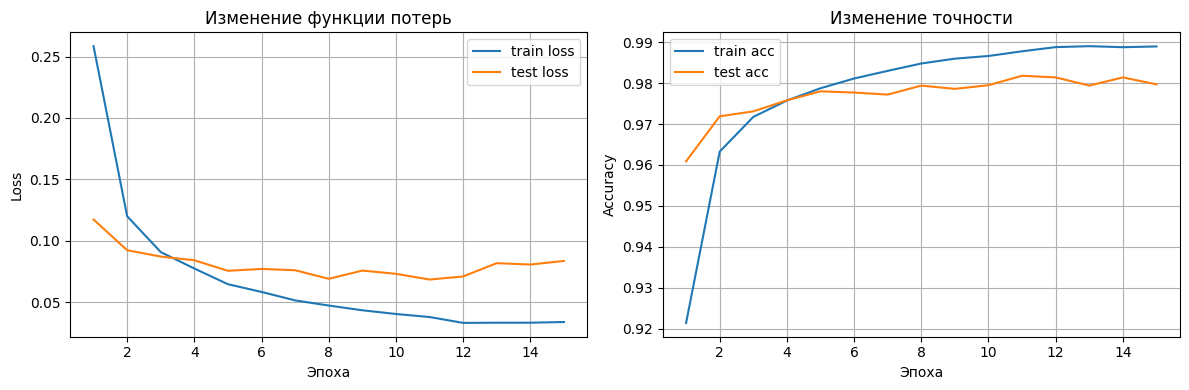

Финальная точность: train=0.9890, test=0.9797


In [75]:
epochs = np.arange(1, num_epochs + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], label="train loss")
plt.plot(epochs, history["test_loss"], label="test loss")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.title("Изменение функции потерь")
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, history["train_acc"], label="train acc")
plt.plot(epochs, history["test_acc"], label="test acc")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.title("Изменение точности")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

print(f"Финальная точность: train={history['train_acc'][-1]:.4f}, test={history['test_acc'][-1]:.4f}")

### Ваш комментарий по кривым обучения

Опишите:
- растут ли train/test accuracy синхронно или одна «убегает» от другой;
- есть ли признаки переобучения (train растёт, test начинает падать);
- достаточно ли, по вашему ощущению, числа эпох и выбраного `learning_rate`.

Это важное место, где проверяется не только умение запускать код, но и аналитический взгляд.


In [80]:
training_comment = """
1. На loss и accuracy в районе 3-4 эпохи близки, но после train "убегает" от test
2. С увеличением числа эпох появляются признаки переобучения. 
3. lr достаточно, оптимальным кол-вом эпох считаю значение в диапазоне от 5 до 10
"""
print(training_comment)


1. На loss и accuracy в районе 3-4 эпохи близки, но после train "убегает" от test
2. С увеличением числа эпох появляются признаки переобучения. 
3. lr достаточно, оптимальным кол-вом эпох считаю значение в диапазоне от 5 до 10



## 8. Ошибки модели: что она путает

Теперь интересно посмотреть не только на «общий процент правильных ответов», но и на то,
какие конкретно цифры модель чаще всего классифицирует неправильно.

Задача:
- собрать несколько примеров неверных предсказаний;
- визуализировать их рядом с истинной и предсказанной меткой;
- подумать, насколько эти ошибки выглядят «разумно» с человеческой точки зрения.


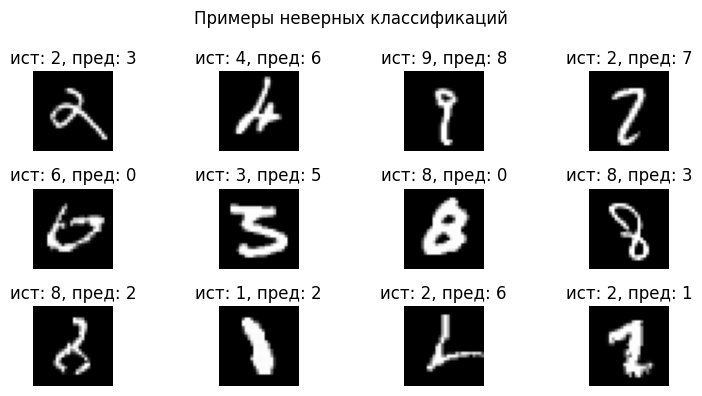

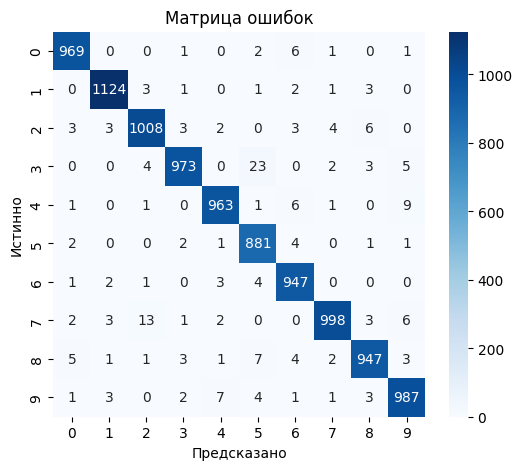

In [77]:
model.eval()
wrong_images = []
wrong_true = []
wrong_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1)

        mismatched = preds != labels
        if mismatched.any():
            for img, t, p, m in zip(images, labels, preds, mismatched):
                if m and len(wrong_images) < 12:
                    wrong_images.append(img.cpu())
                    wrong_true.append(t.cpu().item())
                    wrong_pred.append(p.cpu().item())
        if len(wrong_images) >= 12:
            break

plt.figure(figsize=(8, 4))
for i in range(len(wrong_images)):
    plt.subplot(3, 4, i + 1)
    plt.imshow(wrong_images[i].squeeze().numpy(), cmap="gray")
    plt.title(f"ист: {wrong_true[i]}, пред: {wrong_pred[i]}")
    plt.axis("off")
plt.suptitle("Примеры неверных классификаций")
plt.tight_layout()
plt.show()

from sklearn.metrics import confusion_matrix
import seaborn as sns

all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Предсказано")
plt.ylabel("Истинно")
plt.title("Матрица ошибок")
plt.show()

### Краткий анализ ошибок (заполните сами)

Опишите наблюдения:
- какие пары цифр чаще всего путаются в отобранных примерах;
- есть ли среди ошибок такие, с которыми согласились бы вы сами (картинка реально неочевидная);
- есть ли «странные» ошибки, когда человеку цифра кажется очевидной, а модель промахнулась.


In [78]:
errors_comment = """
1. 3 и 5, 2 и 7
2. Встречается несколько картинок, где ответ действительно не очевиден и ошибка понята
3. Да, большинство из ошибок очевидны были бы человеку
"""
print(errors_comment)


1. 3 и 5, 2 и 7
2. Встречается несколько картинок, где ответ действительно не очевиден и ошибка понята
3. Да, большинство из ошибок очевидны были бы человеку



## 9. Итоговые выводы по лабораторной работе

Эта часть - ключевая для проверки понимания.  
Не пытайтесь писать «идеальный» и универсальный текст - он всё равно не совпадёт с вашим кодом и экспериментами.

Ответьте в свободной форме (примерно 10–15 предложений):
1. Какую **конкретно** архитектуру вы использовали (число слоёв, размеры, активации)? Пробовали ли вы другие варианты и что изменилось?
2. Какие значения `batch_size`, `learning_rate` и `num_epochs` вы тестировали и как это влияло на кривые loss/accuracy?
3. Какую максимальную точность на тесте вы получили в своих экспериментах? Считаете ли вы её удовлетворительной для такой модели?
4. Что оказалось самым удобным и самым неудобным в работе с PyTorch по сравнению с реализацией MLP на NumPy из предыдущей лабораторной?

Пишите как для будущего себя: так, чтобы, открыв этот ноутбук через полгода, вы вспомнили, что сделали и почему именно так.


In [ ]:
final_text = """
1. Входной слой размером 784 (развёрнутое изображение 28×28), затем два скрытых слоя на 256 и 128 нейронов с функцией активации ReLU
Выходной слой на 10 классов. Также был добавлен слой Dropout для уменьшения переобучения.
2. batch_size = 64, learning_rate = 0.001 и num_epochs = 5–10. 
При уменьшении batch_size обучение становилось хуже, при увеличении требовалось больше памяти.
Learning rate 0.001 оказался оптимальным: при большем значении обучение становилось нестабильным, при меньшем - слишком медленным.
3. Максимальная полученная точность ~ 98.2%. Результат удовлетворительный, так как использовался только MLP. 
4. Работа с PyTorch оказалась значительно удобнее по сравнению с реализацией на NumPy. 
Основное преимущество - автоматическое вычисление градиентов, что избавляет от необходимости вручную реализовывать backpropagation. 
Также удобно использовать готовые слои, функции потерь и оптимизаторы. Недостаток лишь в том, что не видно внутренней реализации всех этих компонентов
"""
print(final_text)


1. Входной слой размером 784 (развёрнутое изображение 28×28), затем два скрытых слоя на 256 и 128 нейронов с функцией активации ReLU
Выходной слой на 10 классов. Также был добавлен слой Dropout для уменьшения переобучения.
2. batch_size = 64, learning_rate = 0.001 и num_epochs = 5–10. 
При уменьшении batch_size обучение становилось хуже, при увеличении требовалось больше памяти.
Learning rate 0.001 оказался оптимальным: при большем значении обучение становилось нестабильным, при меньшем — слишком медленным.
3. Максимальная полученная точность ~ 98.2%. Результат удовлетворительный, так как использовался только MLP. 
4. Работа с PyTorch оказалась значительно удобнее по сравнению с реализацией на NumPy. 
Основное преимущество — автоматическое вычисление градиентов, что избавляет от необходимости вручную реализовывать backpropagation. 
Также удобно использовать готовые слои, функции потерь и оптимизаторы. Недостаток лишь в том, что не видно внутренней реализации всех этих компонентов



In [ ]:
 автоматическое вычисление градиентов, что избавляет от необходимости вручную реализовывать backpropagation. 
Также удобно использовать готовые слои, функции потерь и оптимизаторы. Недостаток лишь в том, что не видно внутренней реализации всех этих компонентов
"""
print(final_text)